In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

from pathlib import Path
from skimage.transform import resize
from skimage.feature import hog

from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [6]:
data_root = Path("../data/raw")

mat_files = sorted(
    p for p in data_root.rglob("*.mat")
    if p.name.lower() != "cvind.mat"
)

print(f"Total .mat files: {len(mat_files)}")

Total .mat files: 3064


In [7]:
images = []
labels = []
patient_ids = []

for mat_file in mat_files:

    with h5py.File(mat_file, "r") as f:

        cjdata = f["cjdata"]

        image = np.array(cjdata["image"][()])
        label = int(np.array(cjdata["label"][()]).squeeze())
        pid = np.array(cjdata["PID"][()]).squeeze()

        images.append(image)
        labels.append(label)
        patient_ids.append(str(pid))

print("Images:", len(images))
print("Labels:", len(labels))
print("Patient IDs:", len(patient_ids))

Images: 3064
Labels: 3064
Patient IDs: 3064


In [9]:
# ============================================================
# 4. PREPARE DATASET LABELS
# ============================================================

y = np.array(labels)
groups = np.array(patient_ids)

print("Unique dataset labels:", np.unique(y))
print("Label counts:")
print(pd.Series(y).value_counts().sort_index())

Unique dataset labels: [1 2 3]
Label counts:
1     708
2    1426
3     930
Name: count, dtype: int64


In [10]:
IMAGE_SIZE = (128, 128)

def extract_hog_features(image):

    image = np.asarray(image, dtype=np.float32)

    min_value = image.min()
    max_value = image.max()

    if max_value > min_value:
        image = (image - min_value) / (max_value - min_value)

    image = resize(
        image,
        IMAGE_SIZE,
        anti_aliasing=True
    )

    return hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

In [11]:
X = np.array([
    extract_hog_features(image)
    for image in images
])

print("Feature matrix shape:", X.shape)

Feature matrix shape: (3064, 8100)


In [12]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_test = groups[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(
    "Patient overlap:",
    len(set(groups_train) & set(groups_test))
)

Training samples: 2395
Testing samples: 669
Patient overlap: 0


In [13]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("pca", PCA(
        n_components=0.95,
        random_state=42
    )),

    ("svm", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

In [14]:
svm_params = {
    "svm__C": [1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.001]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train, y_train)

print("Best parameters:", svm_grid.best_params_)
print("Best CV Macro-F1:", svm_grid.best_score_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'svm__C': 10, 'svm__gamma': 'scale'}
Best CV Macro-F1: 0.9564968889658421


In [15]:
svm_model = svm_grid.best_estimator_
svm_pred = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(
    y_test, svm_pred, average="macro"
)
svm_recall = recall_score(
    y_test, svm_pred, average="macro"
)
svm_f1 = f1_score(
    y_test, svm_pred, average="macro"
)

print("===== SVM =====")
print(f"Accuracy        : {svm_accuracy:.4f}")
print(f"Macro Precision : {svm_precision:.4f}")
print(f"Macro Recall    : {svm_recall:.4f}")
print(f"Macro F1        : {svm_f1:.4f}")

print(classification_report(
    y_test,
    svm_pred,
    target_names=[
        "Meningioma",
        "Glioma",
        "Pituitary"
    ]
))

===== SVM =====
Accuracy        : 0.9013
Macro Precision : 0.8651
Macro Recall    : 0.8819
Macro F1        : 0.8723
              precision    recall  f1-score   support

  Meningioma       0.70      0.80      0.74        98
      Glioma       0.92      0.90      0.91       345
   Pituitary       0.98      0.95      0.97       226

    accuracy                           0.90       669
   macro avg       0.87      0.88      0.87       669
weighted avg       0.91      0.90      0.90       669



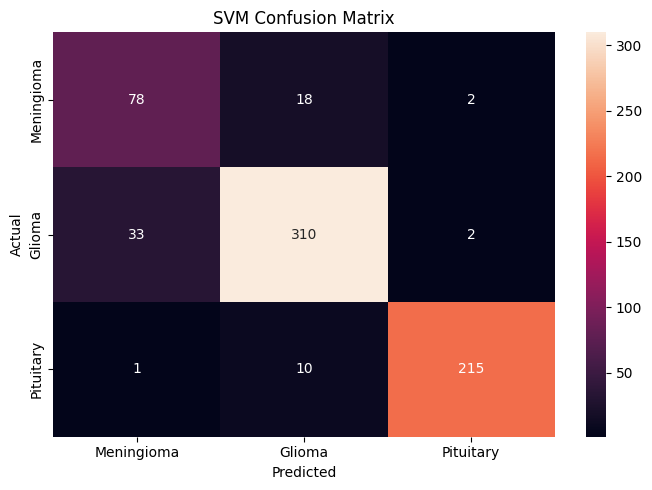

In [16]:
cm_svm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    xticklabels=["Meningioma", "Glioma", "Pituitary"],
    yticklabels=["Meningioma", "Glioma", "Pituitary"]
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [17]:
rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [18]:
rf_params = {
    "n_estimators": [200, 400],
    "max_depth": [None, 20, 40],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print("Best CV Macro-F1:", rf_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
Best CV Macro-F1: 0.8924102264909912


In [19]:
rf_model = rf_grid.best_estimator_
rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(
    y_test, rf_pred, average="macro"
)
rf_recall = recall_score(
    y_test, rf_pred, average="macro"
)
rf_f1 = f1_score(
    y_test, rf_pred, average="macro"
)

print("===== RANDOM FOREST =====")
print(f"Accuracy        : {rf_accuracy:.4f}")
print(f"Macro Precision : {rf_precision:.4f}")
print(f"Macro Recall    : {rf_recall:.4f}")
print(f"Macro F1        : {rf_f1:.4f}")

print(classification_report(
    y_test,
    rf_pred,
    target_names=[
        "Meningioma",
        "Glioma",
        "Pituitary"
    ]
))

===== RANDOM FOREST =====
Accuracy        : 0.8819
Macro Precision : 0.8432
Macro Recall    : 0.8621
Macro F1        : 0.8517
              precision    recall  f1-score   support

  Meningioma       0.69      0.77      0.73        98
      Glioma       0.92      0.87      0.89       345
   Pituitary       0.91      0.95      0.93       226

    accuracy                           0.88       669
   macro avg       0.84      0.86      0.85       669
weighted avg       0.89      0.88      0.88       669



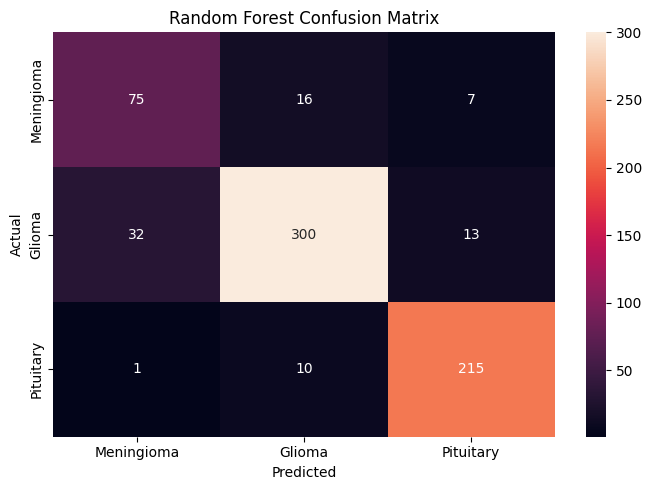

In [20]:
cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    xticklabels=["Meningioma", "Glioma", "Pituitary"],
    yticklabels=["Meningioma", "Glioma", "Pituitary"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [21]:
results = pd.DataFrame({
    "Model": ["SVM", "Random Forest"],
    "Accuracy": [svm_accuracy, rf_accuracy],
    "Macro Precision": [svm_precision, rf_precision],
    "Macro Recall": [svm_recall, rf_recall],
    "Macro F1": [svm_f1, rf_f1]
})

results

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SVM,0.901345,0.865108,0.881932,0.872303
1,Random Forest,0.881913,0.843194,0.862066,0.851699


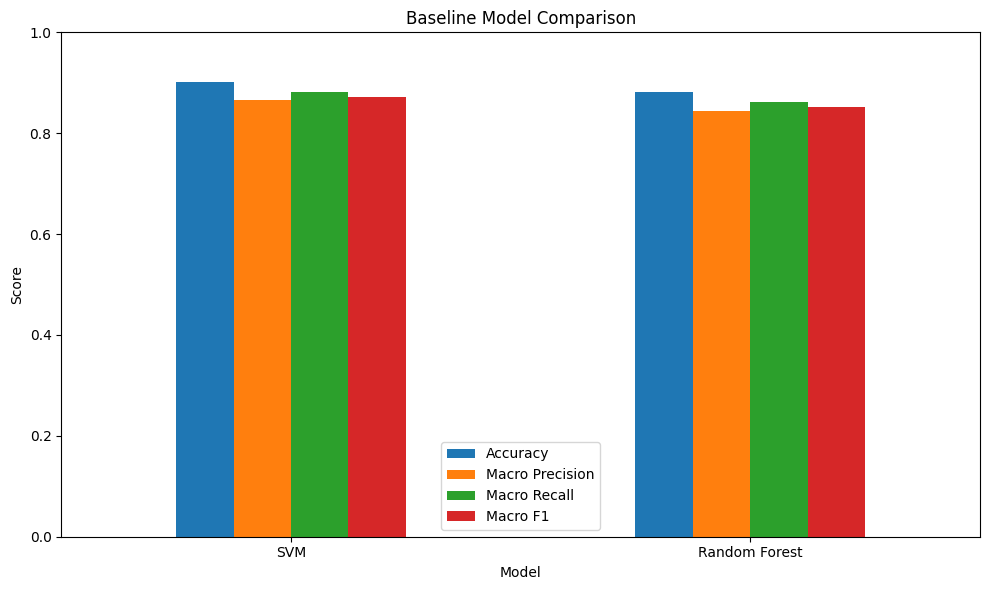

In [22]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Baseline Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
results.to_csv(
    "../results/figshare_baseline_results.csv",
    index=False
)

print("Baseline results saved.")

Baseline results saved.
